# A first nest

From observations to a species-area curve, step by step. Everything here runs offline in a few seconds, on a made-up landscape; the last section shows where your own data go.

In [1]:
import matplotlib.pyplot as plt

import samplesar

plt.rcParams["figure.dpi"] = 80

## Observations

A `Sample` is a set of species observations, each at a longitude and latitude. No real observations ship with samplesar, so `sources.simulated` makes some up: a square of mountain country with a ridge across it, species that each have a home range and a preferred elevation, and visits piled up around a few places, as real observation data are.

In [2]:
sample = samplesar.sources.simulated(seed=1)
sample

Sample(n_observations=1023, n_points=600, n_species=48, area=6088.88)

In [3]:
sample.data.head()

,species,lon,lat,elevation,date
0,Species 32,-83.463658,35.300883,409.1,2009-10-04
1,Species 37,-83.463658,35.300883,409.1,2009-10-04
2,Species 48,-83.463658,35.300883,409.1,2009-10-04
3,Species 03,-83.297310,35.580181,845.6,2006-03-13
4,Species 25,-83.297310,35.580181,845.6,2006-03-13


Records made at one spot differ only by GPS jitter. Left apart, they make the last steps of a nest measure hulls a few meters across. `merge_within` joins points within a distance of each other and keeps every observation.

In [4]:
sample = sample.merge_within(20)   # meters
sample.n_points, sample.n_species, round(sample.area)   # area in km²

(600, 48, 6089)

## Nesting

A strategy removes points step by step. Each step is a smaller sample, with the area of its convex hull and the species still in it. `hull_peel` takes off the whole hull at each step, the points on the outside, so the sample shrinks from its edges inwards.

In [5]:
nest = samplesar.strategies.hull_peel(sample)
nest.to_frame().head(8)

,step,n_points,area,species
0,0,600,6088.878583,48
1,1,582,5731.296993,48
2,2,562,5422.544799,48
3,3,543,4984.006678,48
4,4,527,4556.317142,48
5,5,503,4152.616680,47
6,6,486,3708.859759,46
7,7,465,3459.609954,44


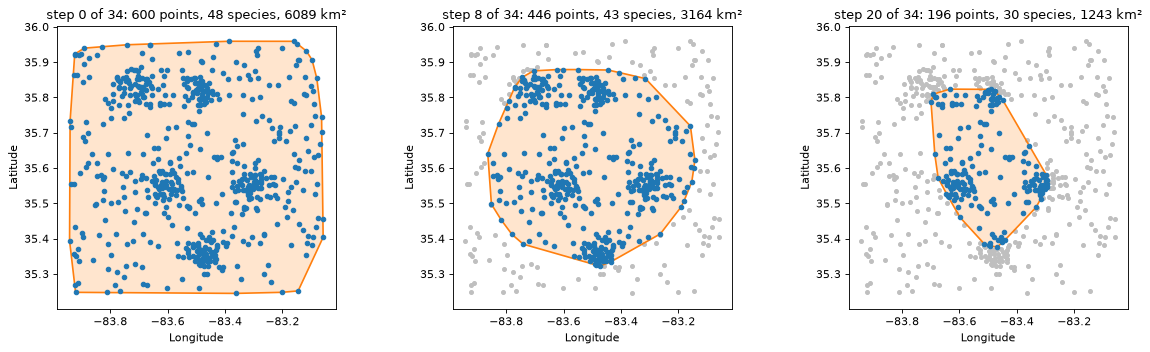

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, step in zip(axes, (0, 8, 20)):
    samplesar.plot.nest(nest, step=step, ax=ax)
fig.tight_layout()

## The species-area curve

`sar_data` is what [sars](https://github.com/jmcmeen/sars) fits: one row of area and species per step. `fit` fits any of its models; `"power"` is $S = cA^z$.

In [7]:
fit = nest.fit("power")
fit.params, float(round(fit.r_squared, 3))

({'c': 1.4756319082190954, 'z': 0.41376682176703744}, 0.949)

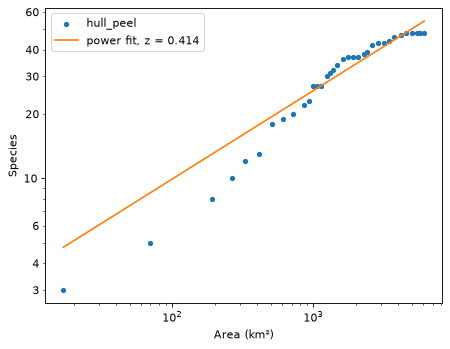

In [8]:
samplesar.plot.curve(nest);

Steps of one nest share most of their points, so they aren't independent observations, and the fit's R² overstates the evidence. [Comparing strategies](strategies.ipynb) shows how to judge a nest against random ones instead.

## Measuring within a mask

A convex hull can span ground that isn't habitat: sea along a coast, a lake. With a mask, every area is the hull's part inside it. Here the "land" is everything east of a made-up shoreline.

In [9]:
from shapely.geometry import box

land = box(-83.80, 35.0, -82.5, 36.5)
on_land = sample.within(land, mask=True)   # keep the observations on land, and measure there
masked = samplesar.strategies.hull_peel(on_land)
masked.to_frame().head(4)   # area: within the mask; hull_area: the whole hull

,step,n_points,area,species,hull_area
0,0,545,5070.300836,47,5070.300836
1,1,526,4647.311062,46,4647.311062
2,2,506,4372.441999,46,4372.441999
3,3,491,4001.179086,45,4001.179086


## Saving a nest

A nest saves as JSON, with its observations, its strategy and every step, and loads back the same.

In [10]:
import tempfile
from pathlib import Path

path = Path(tempfile.mkdtemp()) / "nest.json"
nest.to_json(path)
again = samplesar.Nest.from_json(path)
again.label, again.n_steps == nest.n_steps

('hull_peel', True)

## Your own data

```python
sample = samplesar.sources.csv("observations.csv")        # columns species, lon, lat
sample = samplesar.sources.dataframe(df, species_col="taxon", lon_col="x", lat_col="y", crs="EPSG:32617")
sample = samplesar.sources.inaturalist(taxon_id=20979, place_id=45, quality_grade="research")
sample = samplesar.sources.gbif(taxonKey=952, country="CR")
```

and a region to restrict it to, or to mask its areas with:

```python
costa_rica = samplesar.regions.admin("CRI")
sample = sample.within(costa_rica, mask=True)
```